# Variational Autoencoder (VAE) do zero em PyTorch

Implementação do VAE seguindo a §20.3.5 do *Probabilistic Machine Learning: An Introduction* (Murphy, 2022), treinado no MNIST (70 mil imagens de dígitos escritos à mão, 28 × 28 pixels; aqui uso as 60 mil de treino). O dataset é baixado automaticamente pelo `torchvision` na primeira execução.

A arquitetura (784 → 400 → 2 → 400 → 784) é a clássica para esse problema. Escolhi um espaço latente de só 2 dimensões para poder visualizar a grade no final.

Depois apliquei a mesma ideia em dados reais, usando o VAE para detectar fraude em cartão de crédito: ver `fraude_pca_autoencoder_vae.ipynb`.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

transform = transforms.ToTensor()
train_mnist = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
loader = DataLoader(train_mnist, batch_size=128, shuffle=True)

100.0%
100.0%
100.0%
100.0%


In [2]:
class VAE(nn.Module):
    def __init__(self, n_input=784, n_hidden=400, n_latent=2):
        super().__init__()
        # encoder
        self.fc1 = nn.Linear(n_input, n_hidden)
        self.fc_mu = nn.Linear(n_hidden, n_latent)      # produz μ
        self.fc_logvar = nn.Linear(n_hidden, n_latent)  # produz log σ²
        # decoder
        self.fc3 = nn.Linear(n_latent, n_hidden)
        self.fc4 = nn.Linear(n_hidden, n_input)

    def encode(self, x):
        h = F.relu(self.fc1(x))                  # a não-linearidade
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std                    

    def decode(self, z):
        h = F.relu(self.fc3(z))
        return torch.sigmoid(self.fc4(h))        # pixels em [0,1]

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

In [3]:
def perda_vae(x_rec, x, mu, logvar):
    # termo 1: reconstrução (verossimilhança Bernoulli, eq. 20.95)
    recon = F.binary_cross_entropy(x_rec, x, reduction="sum")
    # termo 2: KL entre a posterior aproximada e a prior N(0,I)
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon + kl

In [4]:
modelo = VAE()
otim = torch.optim.Adam(modelo.parameters(), lr=1e-3)

for epoca in range(10):
    total = 0
    for xb, _ in loader:
        xb = xb.view(-1, 784)          
        x_rec, mu, logvar = modelo(xb)
        perda = perda_vae(x_rec, xb, mu, logvar)
        otim.zero_grad()
        perda.backward()
        otim.step()
        total += perda.item()
    print(f"época {epoca}: perda média = {total/len(train_mnist):.2f}")

época 0: perda média = 190.24
época 1: perda média = 167.62
época 2: perda média = 163.65
época 3: perda média = 161.47
época 4: perda média = 159.85
época 5: perda média = 158.60
época 6: perda média = 157.51
época 7: perda média = 156.43
época 8: perda média = 155.64
época 9: perda média = 154.84


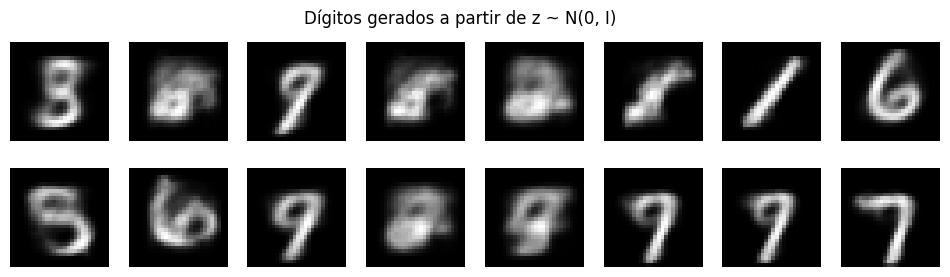

In [5]:
modelo.eval()
with torch.no_grad():
    z = torch.randn(16, 2)              
    amostras = modelo.decode(z)

fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i, ax in enumerate(axes.flat):
    ax.imshow(amostras[i].view(28, 28), cmap="gray")
    ax.axis("off")
plt.suptitle("Dígitos gerados a partir de z ~ N(0, I)")
plt.show()

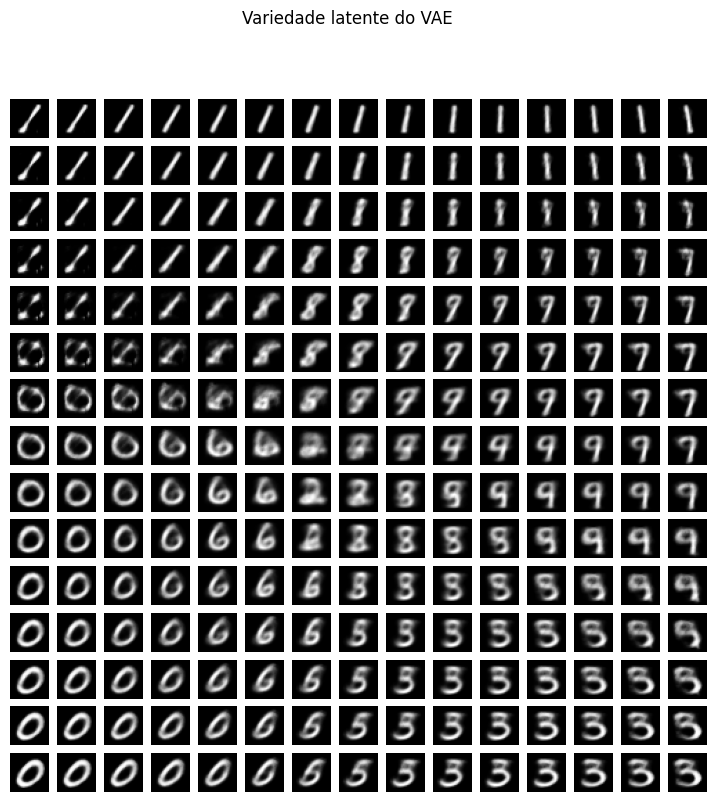

In [6]:
n = 15
grid = torch.linspace(-2.5, 2.5, n)
fig, axes = plt.subplots(n, n, figsize=(9, 9))
with torch.no_grad():
    for i, yi in enumerate(grid):
        for j, xj in enumerate(grid):
            img = modelo.decode(torch.tensor([[xj, yi]]))
            axes[i, j].imshow(img.view(28, 28), cmap="gray")
            axes[i, j].axis("off")
plt.suptitle("Variedade latente do VAE")
plt.show()

O VAE (Variational Autoencoder, ou autoencoder variacional) foi implementado do zero em PyTorch, seguindo §20.3.5 (p. 683-685). Diferente do autoencoder determinístico, o encoder produz uma distribuição — média e log-variância (eq. 20.96) — em vez de um ponto no espaço latente.

Duas peças foram necessárias para o treino. O reparameterization trick, que substitui a amostragem direta de N(μ, σ²) por μ + ε·σ com ε ~ N(0,1), tornando a operação diferenciável e permitindo que o gradiente flua. E o ELBO (eq. 20.98), composto de dois termos: reconstrução (verossimilhança Bernoulli) e a divergência KL entre a posterior aproximada e a prior N(0,I), que atua como regularizador.

Com 10 épocas, a perda caiu de 190,24 para 154,84.

O resultado principal é a capacidade generativa, que o livro aponta como vantagem central do VAE. Sorteando z ~ N(0,I) e passando apenas pelo decoder, o modelo gera dígitos que não existem no dataset — nenhuma imagem real entra nesse processo.

A varredura do espaço latente em grade mostra o efeito do termo KL: cada dígito ocupa uma região contígua (1s no topo, 0s à esquerda, 7s e 9s à direita, 3s embaixo) e as transições entre regiões são contínuas. O modelo descobriu essa organização sem ver nenhum rótulo. É o espaço latente estruturado que viabiliza a geração — no autoencoder determinístico, nada garante que um z sorteado caia numa região com significado.

As amostras são borradas, o que tem duas causas: apenas 2 dimensões latentes (escolhidas para permitir a visualização em grade) e uma característica conhecida de VAEs, que tendem a produzir médias entre modos quando incertos.

## Referências

- Murphy, K. P. *Probabilistic Machine Learning: An Introduction*. MIT Press, 2022. §20.3.5.
- Kingma, D. P.; Welling, M. *Auto-Encoding Variational Bayes*. ICLR, 2014.
- LeCun, Y.; Cortes, C.; Burges, C. J. C. *The MNIST database of handwritten digits*.